In [1]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 3.1 MB/s eta 0:00:03
   ------ --------------------------------- 1.3/8.2 MB 3.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.1/8.2 MB 3.8 MB/s eta 0:00:02
   ---------------- ----------------------- 3.4/8.2 MB 4.2 MB/s eta 0:00:02
   -------------------- ------------------- 4.2/8.2 MB 4.2 MB/s eta 0:00:01
   ------------------------- -------------- 5.2/8.2 MB 4.4 MB/s eta 0:00:01
   ----------------------------- ---------- 6.0/8.2 MB 4.4 MB/s eta 0:00:01
   ---------------------------------- ----- 7.1/8.2 MB 4.4 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 4.5 MB/s  0:00:01

   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- -


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn common modules for Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_squared_error, r2_score

# Additional Requested Scikit-Learn Modules
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn import linear_model

# Configure plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Essential EDA and ML libraries (including pipeline, compose, impute, linear_model) successfully imported!")

Essential EDA and ML libraries (including pipeline, compose, impute, linear_model) successfully imported!


In [3]:
rng = np.random.default_rng(42)            # fixed seed -> same data for everyone
n = 200

size_sqft = rng.integers(500, 3000, n).astype(float)                       # house size
bedrooms  = np.clip((size_sqft / 700 + rng.integers(-1, 2, n)).round(), 1, 5).astype(int)
age_years = rng.integers(0, 40, n).astype(float)                           # house age
location  = rng.choice(["Urban", "Suburban", "Rural"], n, p=[0.4, 0.4, 0.2])
loc_bonus = pd.Series(location).map({"Urban": 15, "Suburban": 5, "Rural": 0}).to_numpy()

# Price in lakhs: depends on size, bedrooms, age, location + random noise
price_lakhs = (10 + 0.05 * size_sqft + 4 * bedrooms - 0.4 * age_years
               + loc_bonus + rng.normal(0, 8, n)).round(2)

df = pd.DataFrame({
    "size_sqft": size_sqft,
    "bedrooms": bedrooms,
    "age_years": age_years,
    "location": location,
    "price_lakhs": price_lakhs
})

# Make the data messy on purpose (like real life)
df = pd.concat([df, df.iloc[:3]], ignore_index=True)                   # 3 duplicate rows
df.loc[rng.choice(np.arange(10, n), 8, replace=False), "size_sqft"] = np.nan   # 8 missing sizes
df.loc[rng.choice(np.arange(10, n), 10, replace=False), "age_years"] = np.nan  # 10 missing ages

print("Dataset created. Target column = 'price_lakhs'")
df.head()

Dataset created. Target column = 'price_lakhs'


,size_sqft,bedrooms,age_years,location,price_lakhs
0,723.0,1,39.0,Suburban,51.02
1,2434.0,4,31.0,Urban,151.03
2,2136.0,3,12.0,Suburban,133.65
3,1597.0,3,38.0,Suburban,91.20
4,1582.0,2,19.0,Rural,88.14


In [4]:
# Cell 3: First look at the data
print("Shape (rows, columns):", df.shape)
print("\n--- Data types and non-null counts ---")
df.info()
print("\n--- Summary statistics (numeric columns) ---")
df.describe()

Shape (rows, columns): (203, 5)

--- Data types and non-null counts ---
<class 'pandas.DataFrame'>
RangeIndex: 203 entries, 0 to 202
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   size_sqft    195 non-null    float64
 1   bedrooms     203 non-null    int64  
 2   age_years    193 non-null    float64
 3   location     203 non-null    str    
 4   price_lakhs  203 non-null    float64
dtypes: float64(3), int64(1), str(1)
memory usage: 8.1 KB

--- Summary statistics (numeric columns) ---


,size_sqft,bedrooms,age_years,price_lakhs
count,195.000000,203.000000,193.000000,203.000000
mean,1777.835897,2.532020,19.854922,107.911921
std,692.581004,1.170051,12.218057,39.151901
min,518.000000,1.000000,0.000000,34.100000
25%,1211.500000,2.000000,9.000000,74.960000
50%,1762.000000,2.000000,20.000000,106.160000
75%,2407.000000,3.000000,32.000000,140.960000
max,2990.000000,5.000000,39.000000,182.470000


In [5]:
# Cell 4: Check and fix data quality problems
print("Missing values per column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)   # remove duplicates
print("Shape after removing duplicates:", df.shape)

numerical_cols   = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()
print("\nNumerical columns :", numerical_cols)
print("Categorical columns:", categorical_cols)

Missing values per column:
size_sqft       8
bedrooms        0
age_years      10
location        0
price_lakhs     0
dtype: int64

Number of duplicate rows: 3
Shape after removing duplicates: (200, 5)

Numerical columns : ['size_sqft', 'bedrooms', 'age_years', 'price_lakhs']
Categorical columns: ['location']


C:\Users\paulc\AppData\Local\Temp\ipykernel_13620\3790401166.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


In [6]:
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("\nNumerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)


Numerical columns: ['size_sqft', 'bedrooms', 'age_years', 'price_lakhs']
Categorical columns: ['location']


C:\Users\paulc\AppData\Local\Temp\ipykernel_13620\3730513361.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


In [7]:
# Check the shape after dropping duplicates
print(df.shape)

(200, 5)


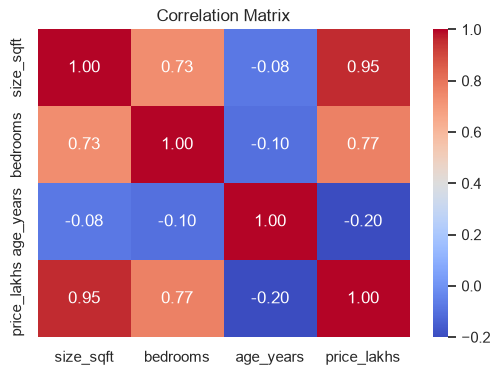

In [8]:
# Cell 6: Correlation matrix (numeric columns only)
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()